# Tasks for laboratory assignment 3

In [1]:
# imports section

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures

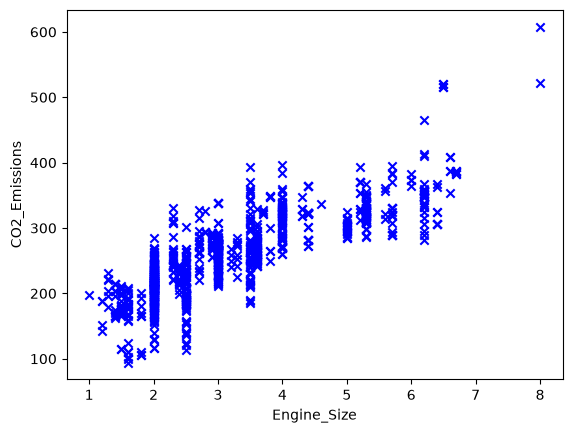

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    return pd.read_csv(file_path)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

CO2 = 135.33 + 38.32 * Engine_Size
R^2 = 0.682


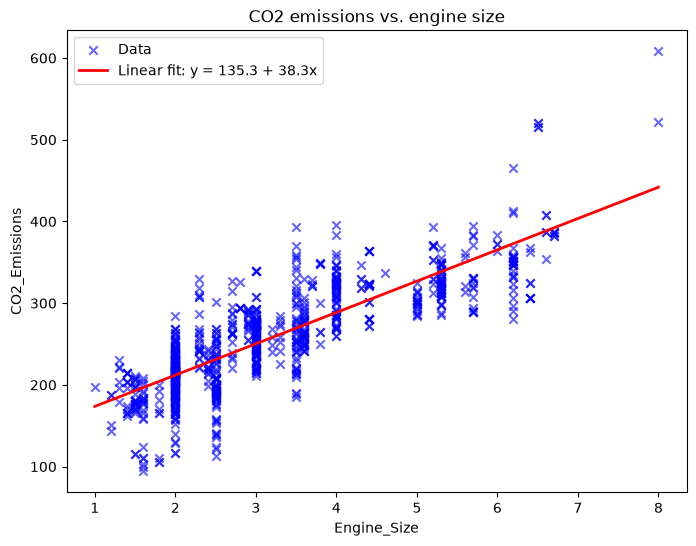

[135.3260546026322, 38.32301106042744]

In [4]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car.
    Visualize model on a plot.

    Args:
        data: CO2 emissions data (CSV text, list of CSV lines, or DataFrame).

    Returns:
        list: The list of model theta parameters [theta_0 (intercept), theta_1 (slope)].
    """
    df = data.copy()

    df = df[["Engine_Size", "CO2_Emissions"]].apply(pd.to_numeric, errors="coerce").dropna()

    X = df[["Engine_Size"]].values
    y = df["CO2_Emissions"].values

    model = LinearRegression()
    model.fit(X, y)

    theta_0 = float(model.intercept_)
    theta_1 = float(model.coef_[0])
    print(f"CO2 = {theta_0:.2f} + {theta_1:.2f} * Engine_Size")
    print(f"R^2 = {r2_score(y, model.predict(X)):.3f}")

    x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    plt.figure(figsize=(8, 6))
    plt.scatter(X, y, color="blue", marker="x", alpha=0.6, label="Data")
    plt.plot(x_line, model.predict(x_line), color="red", linewidth=2,
             label=f"Linear fit: y = {theta_0:.1f} + {theta_1:.1f}x")
    plt.xlabel("Engine_Size")
    plt.ylabel("CO2_Emissions")
    plt.title("CO2 emissions vs. engine size")
    plt.legend()
    plt.show()

    return [theta_0, theta_1]


data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

theta (intercept, T, T^2): [np.float64(2.9517741579934444), np.float64(-0.8246816702106483), np.float64(1.8295262296702086)]
Train R^2: 0.9321137090423877


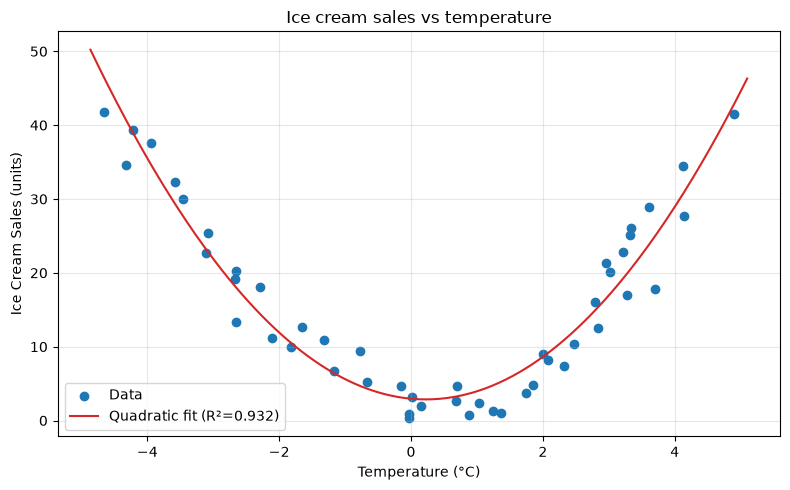

[np.float64(2.9517741579934444),
 np.float64(-0.8246816702106483),
 np.float64(1.8295262296702086)]

In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline

def ice_cream_selling(data):
    """
    Build a model that predicts ice cream sales from temperature and plot it.
 
    Returns:
        list: theta parameters [theta0, theta1, theta2] of
              sales = theta0 + theta1 * T + theta2 * T^2
    """
    X = data.iloc[:, [0]].values
    y = data.iloc[:, 1].values

    poly = PolynomialFeatures(degree=2, include_bias=False)
    Xp = poly.fit_transform(X)
    model = LinearRegression().fit(Xp, y)
    theta = [model.intercept_, *model.coef_]
    print("theta (intercept, T, T^2):", theta)
    print("Train R^2:", model.score(Xp, y))
 
    grid = np.linspace(X.min() - 0.2, X.max() + 0.2, 300).reshape(-1, 1)
    plt.figure(figsize=(8, 5))
    plt.scatter(X, y, label="Data", color="tab:blue")
    plt.plot(grid, model.predict(poly.transform(grid)), color="tab:red",
             label=f"Quadratic fit (R²={model.score(Xp, y):.3f})")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Ice Cream Sales (units)")
    plt.title("Ice cream sales vs temperature")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
 
    return theta

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Here we predict comsumption for sum of three PowerConsumption_Zones

linear             CV R^2 = 0.245
poly degree 2      CV R^2 = 0.288
poly degree 3      CV R^2 = 0.301
gradient boosting  CV R^2 = 0.367

terms: ['1', 'Temperature', 'Humidity', 'WindSpeed', 'Temperature^2', 'Temperature Humidity', 'Temperature WindSpeed', 'Humidity^2', 'Humidity WindSpeed', 'WindSpeed^2']
theta: [97180.0156701311, -3674.4007961319526, 0.3568606496218507, -14065.292130800412, 78.11773664664844, 29.935957462513215, 89.63566636478731, -4.705067833946032, -27.828369027176123, 2776.584040866084]
Train R^2 = 0.288


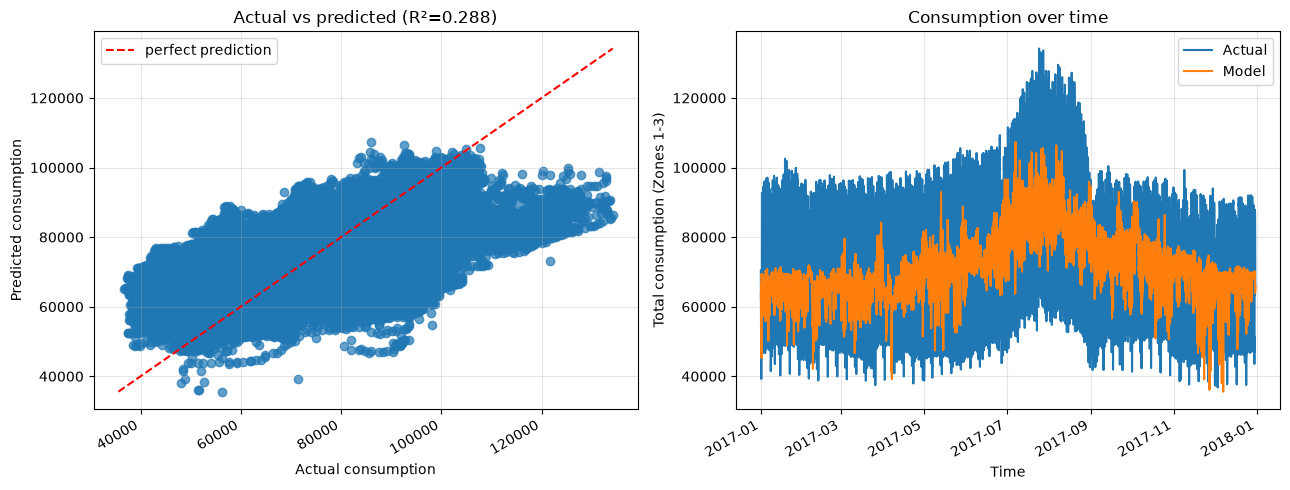

[97180.0156701311,
 -3674.4007961319526,
 0.3568606496218507,
 -14065.292130800412,
 78.11773664664844,
 29.935957462513215,
 89.63566636478731,
 -4.705067833946032,
 -27.828369027176123,
 2776.584040866084]

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline

FEATURES = ["Temperature", "Humidity", "WindSpeed"]
ZONES = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]

def power_consumption(data):
    """
    Build a model that predicts total electricity consumption (sum of the three
    zones) from temperature, humidity and wind speed. Visualize the model.

    Returns:
        list: theta parameters of the degree-2 polynomial model, in the order
              given by the printed feature names (intercept first).
    """
    X = data[FEATURES].values
    y = data[ZONES].sum(axis=1).values

    # Model comparison (5-fold CV, R^2). Rows are 10 minutes apart, so shuffled
    # folds are optimistic; treat the numbers as a relative comparison.
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    candidates = {
        "linear": make_pipeline(LinearRegression()),
        "poly degree 2": make_pipeline(PolynomialFeatures(2), LinearRegression()),
        "poly degree 3": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    }
    for name, m in candidates.items():
        score = cross_val_score(m, X, y, cv=cv, scoring="r2").mean()
        print(f"{name:18s} CV R^2 = {score:.3f}")

    # Final model: degree-2 polynomial regression (interpretable parameters)
    poly = PolynomialFeatures(degree=2)
    Xp = poly.fit_transform(X)
    model = LinearRegression(fit_intercept=False).fit(Xp, y)
    theta = model.coef_.tolist()
    y_pred = Xp @ model.coef_
    r2 = model.score(Xp, y)

    print("\nterms:", list(poly.get_feature_names_out(FEATURES)))
    print("theta:", theta)
    print(f"Train R^2 = {r2:.3f}")

    # Plot: actual vs predicted, and both over time
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    ax[0].scatter(y, y_pred, alpha=0.7)
    lim = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    ax[0].plot(lim, lim, "r--", label="perfect prediction")
    ax[0].set_xlabel("Actual consumption")
    ax[0].set_ylabel("Predicted consumption")
    ax[0].set_title(f"Actual vs predicted (R²={r2:.3f})")
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    t = pd.to_datetime(data["Datetime"], format="%m/%d/%Y %H:%M")
    ax[1].plot(t, y, label="Actual")
    ax[1].plot(t, y_pred, label="Model")
    ax[1].set_xlabel("Time")
    ax[1].set_ylabel("Total consumption (Zones 1-3)")
    ax[1].set_title("Consumption over time")
    ax[1].legend()
    ax[1].grid(alpha=0.3)
    fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()

    return theta

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

Here we predict consumption for each zone separately

terms: ['1', 'Temperature', 'Humidity', 'WindSpeed', 'Temperature^2', 'Temperature Humidity', 'Temperature WindSpeed', 'Humidity^2', 'Humidity WindSpeed', 'WindSpeed^2']

=== PowerConsumption_Zone1 ===
linear             CV R^2 = 0.204
poly degree 2      CV R^2 = 0.227
poly degree 3      CV R^2 = 0.234
gradient boosting  CV R^2 = 0.293
theta: [36563.1950681476, -754.0378496661203, 5.619308495986022, -2995.486953675284, 15.858238786378784, 10.409883457787373, 6.905794644506193, -1.8146433452035353, -11.27673102950784, 685.9489092284259]
Train R^2 = 0.228

=== PowerConsumption_Zone2 ===
linear             CV R^2 = 0.164
poly degree 2      CV R^2 = 0.196
poly degree 3      CV R^2 = 0.214
gradient boosting  CV R^2 = 0.279
theta: [28179.79515590291, -892.950898937442, 25.92081425326241, -3487.79360789413, 18.093551460323553, 7.456789507753456, 22.09545664816366, -1.6266071252905476, -3.6469214062293354, 633.7876680437423]
Train R^2 = 0.197

=== PowerConsumption_Zone3 ===
linear             

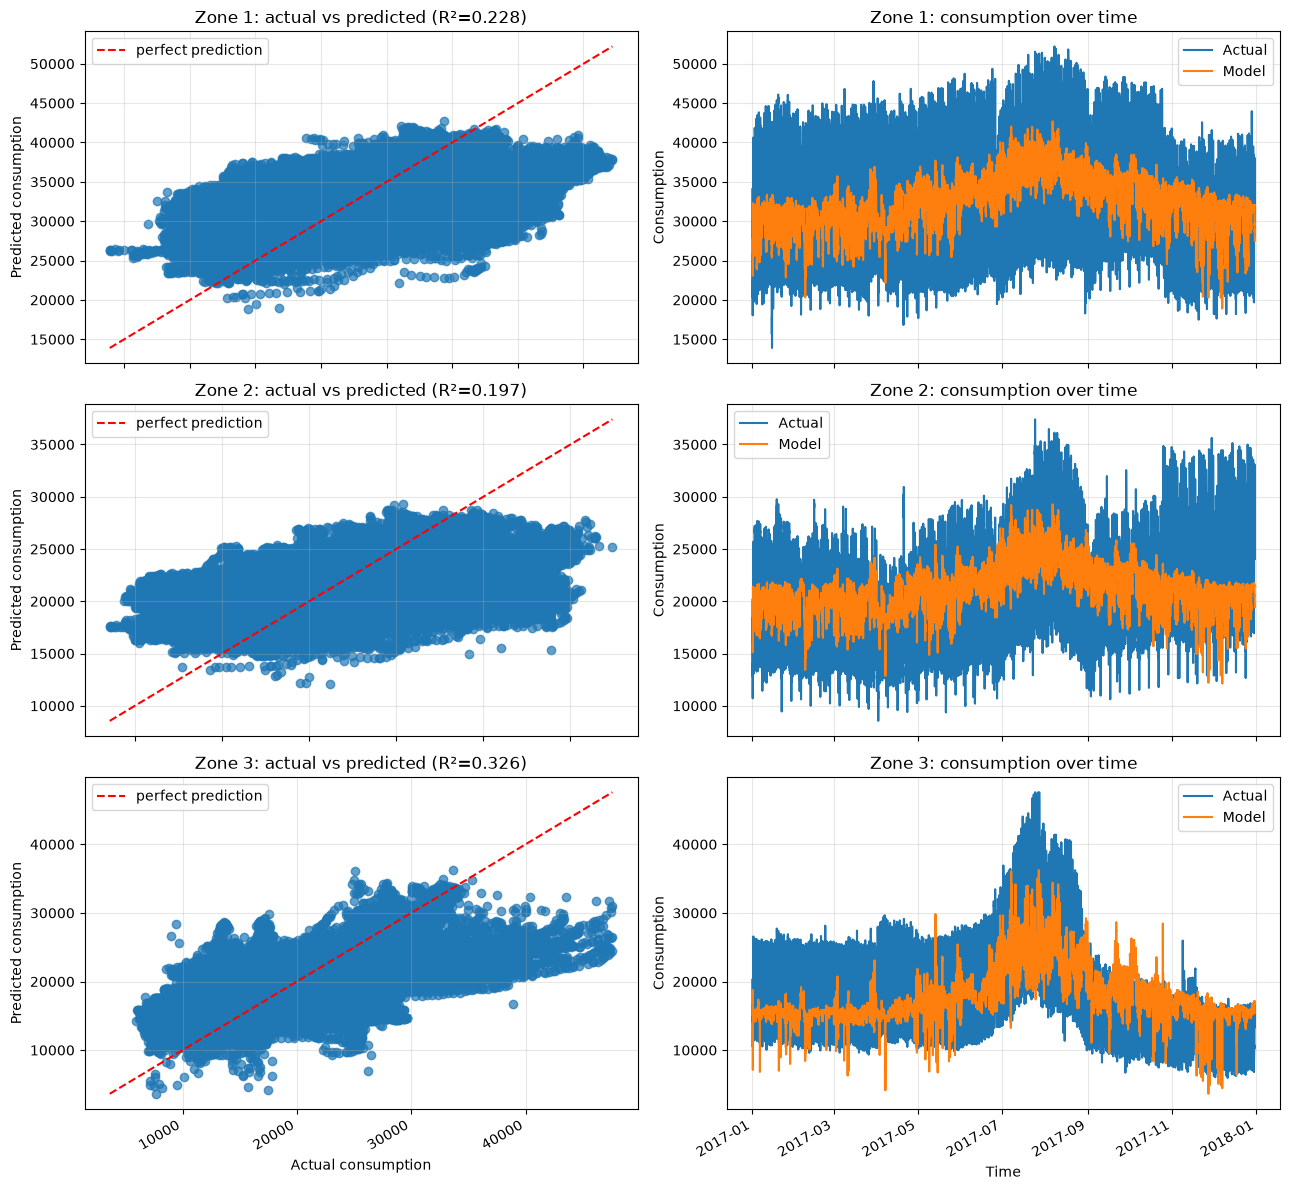

[[36563.1950681476,
  -754.0378496661203,
  5.619308495986022,
  -2995.486953675284,
  15.858238786378784,
  10.409883457787373,
  6.905794644506193,
  -1.8146433452035353,
  -11.27673102950784,
  685.9489092284259],
 [28179.79515590291,
  -892.950898937442,
  25.92081425326241,
  -3487.79360789413,
  18.093551460323553,
  7.456789507753456,
  22.09545664816366,
  -1.6266071252905476,
  -3.6469214062293354,
  633.7876680437423],
 [32437.02544608065,
  -2027.4120475283926,
  -31.183262099627164,
  -7582.011569231004,
  44.165946399947785,
  12.069284496971193,
  60.634415072117505,
  -1.2638173634525174,
  -12.904716591439964,
  1456.8474635939137]]

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline

FEATURES = ["Temperature", "Humidity", "WindSpeed"]
ZONES = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]


def power_consumption(data):
    """
    Build a separate model for each zone that predicts its electricity
    consumption from temperature, humidity and wind speed. Visualize the models.

    Returns:
        list: one list of theta parameters per zone (Zone 1, 2, 3). Each model is
              a degree-2 polynomial regression; term order is printed below.
    """
    X = data[FEATURES].values
    t = pd.to_datetime(data["Datetime"], format="%m/%d/%Y %H:%M")

    # Rows are 10 minutes apart, so shuffled folds are optimistic; treat the CV
    # numbers as a relative comparison between models.
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    candidates = {
        "linear": make_pipeline(LinearRegression()),
        "poly degree 2": make_pipeline(PolynomialFeatures(2), LinearRegression()),
        "poly degree 3": make_pipeline(PolynomialFeatures(3), LinearRegression()),
        "gradient boosting": GradientBoostingRegressor(random_state=0),
    }

    poly = PolynomialFeatures(degree=2)
    Xp = poly.fit_transform(X)
    print("terms:", list(poly.get_feature_names_out(FEATURES)))

    fig, axes = plt.subplots(len(ZONES), 2, figsize=(13, 4 * len(ZONES)))
    all_theta = []

    for i, zone in enumerate(ZONES):
        y = data[zone].values
        print(f"\n=== {zone} ===")
        for name, m in candidates.items():
            score = cross_val_score(m, X, y, cv=cv, scoring="r2").mean()
            print(f"{name:18s} CV R^2 = {score:.3f}")

        # Final model for this zone: degree-2 polynomial regression
        model = LinearRegression(fit_intercept=False).fit(Xp, y)
        theta = model.coef_.tolist()
        y_pred = Xp @ model.coef_
        r2 = model.score(Xp, y)
        all_theta.append(theta)
        print("theta:", theta)
        print(f"Train R^2 = {r2:.3f}")

        ax_scatter, ax_time = axes[i]
        ax_scatter.scatter(y, y_pred, alpha=0.7)
        lim = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
        ax_scatter.plot(lim, lim, "r--", label="perfect prediction")
        ax_scatter.set_xlabel("Actual consumption")
        ax_scatter.set_ylabel("Predicted consumption")
        ax_scatter.set_title(f"Zone {i + 1}: actual vs predicted (R²={r2:.3f})")
        ax_scatter.legend()
        ax_scatter.grid(alpha=0.3)

        ax_time.plot(t, y, label="Actual")
        ax_time.plot(t, y_pred, label="Model")
        ax_time.set_xlabel("Time")
        ax_time.set_ylabel("Consumption")
        ax_time.set_title(f"Zone {i + 1}: consumption over time")
        ax_time.legend()
        ax_time.grid(alpha=0.3)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return all_theta



data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

Here we predict consumption using time and weather


=== PowerConsumption_Zone1 ===
linear, weather only       CV R^2 = 0.203
linear, weather + time     CV R^2 = 0.667
boosting, weather only     CV R^2 = 0.239
boosting, weather + time   CV R^2 = 0.959
-> best: boosting, weather + time

=== PowerConsumption_Zone2 ===
linear, weather only       CV R^2 = 0.162
linear, weather + time     CV R^2 = 0.606
boosting, weather only     CV R^2 = 0.217
boosting, weather + time   CV R^2 = 0.949
-> best: boosting, weather + time

=== PowerConsumption_Zone3 ===
linear, weather only       CV R^2 = 0.241
linear, weather + time     CV R^2 = 0.600
boosting, weather only     CV R^2 = 0.408
boosting, weather + time   CV R^2 = 0.977
-> best: boosting, weather + time


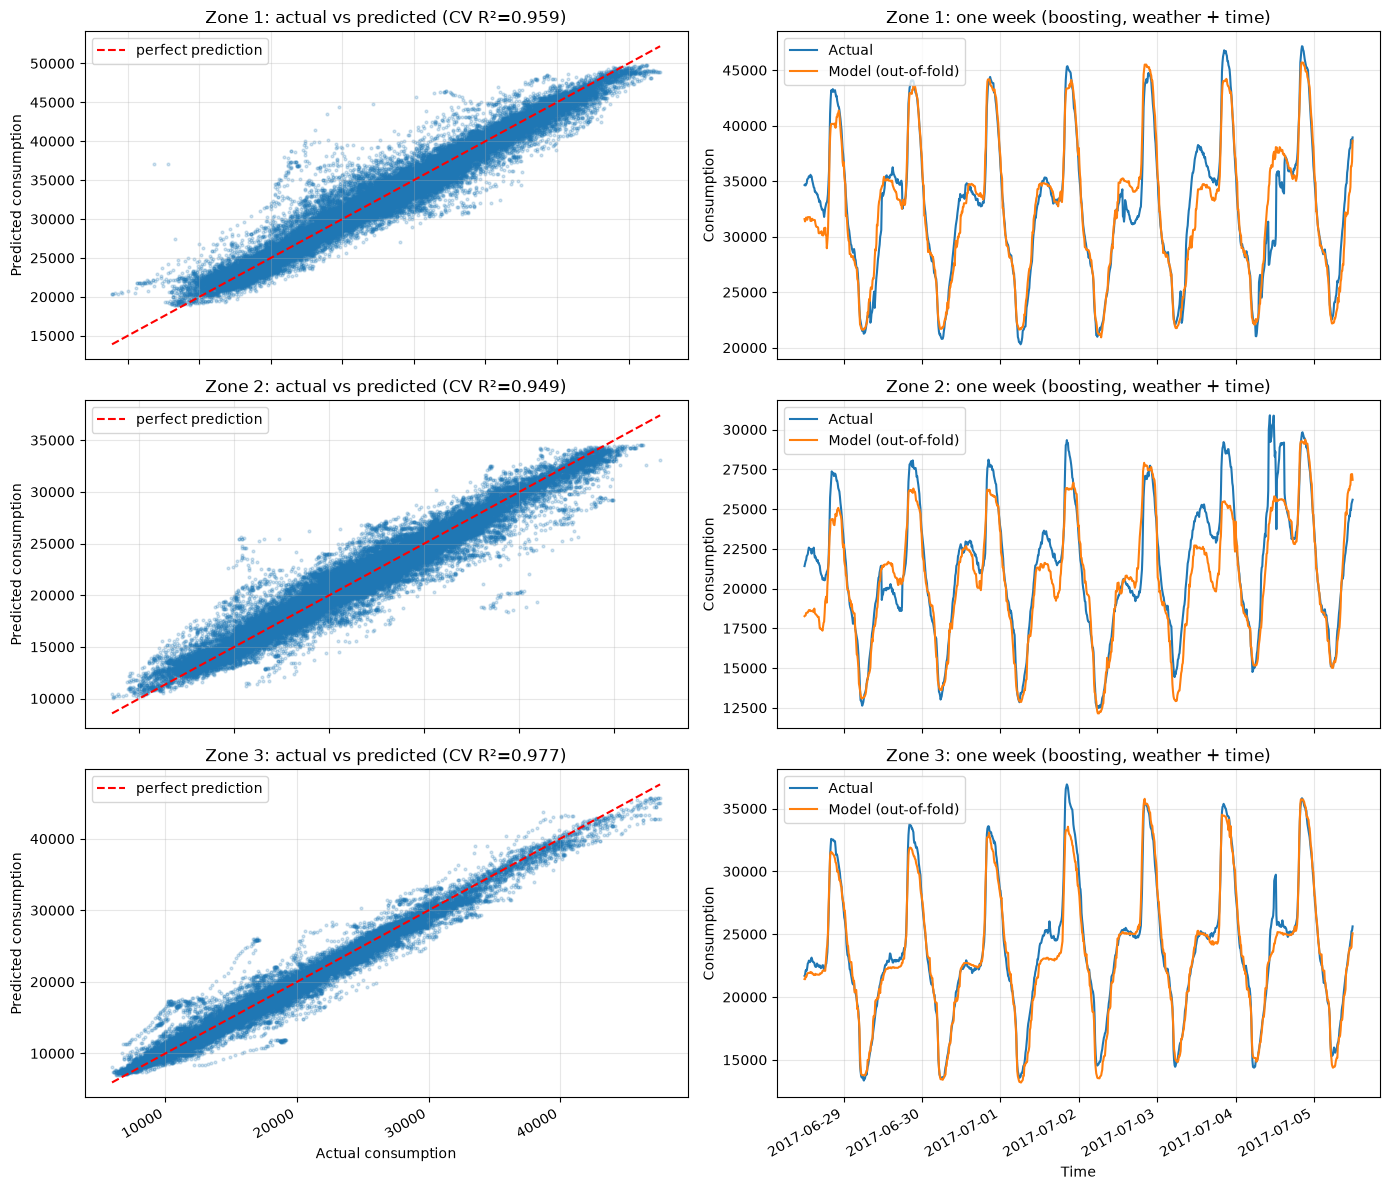

[HistGradientBoostingRegressor(random_state=0),
 HistGradientBoostingRegressor(random_state=0),
 HistGradientBoostingRegressor(random_state=0)]

In [11]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, KFold, cross_val_score, cross_val_predict

WEATHER = ["Temperature", "Humidity", "WindSpeed"]
TIME = ["hour_sin", "hour_cos", "dow", "is_weekend", "doy_sin", "doy_cos"]
ZONES = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]


def extract_texts_from_file(file_path):
    """Read the csv file and return a DataFrame."""
    return pd.read_csv(file_path)


def add_time_features(data):
    """Add cyclic hour-of-day, day-of-week and seasonal (day-of-year) features."""
    t = pd.to_datetime(data["Datetime"], format="%m/%d/%Y %H:%M")
    hour = t.dt.hour + t.dt.minute / 60
    doy = t.dt.dayofyear
    df = data.copy()
    # cyclic encoding: 23:00 and 00:00 end up close to each other
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    df["dow"] = t.dt.dayofweek                      # 0 = Monday
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(int)
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)  # seasonal effect
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    df["_time"] = t
    df["_date"] = t.dt.date
    return df


def make_cv(groups):
    """Folds made of whole days, so neighbouring 10-minute rows never leak
    between train and test."""
    n_days = groups.nunique()
    if n_days >= 5:
        return GroupKFold(n_splits=5), groups
    warnings.warn("Fewer than 5 distinct days in the data: falling back to "
                  "shuffled K-fold, scores will be optimistic.")
    return KFold(n_splits=5, shuffle=True, random_state=0), None


def power_consumption(data):
    """
    Build a separate model for each zone that predicts electricity consumption
    from the weather (temperature, humidity, wind speed) plus time features
    (hour of day, day of week, season). Visualize the models.

    Returns:
        list: one fitted model per zone (Zone 1, 2, 3), each the best model
              found by cross-validation for that zone.
    """
    df = add_time_features(data)
    cv, groups = make_cv(df["_date"])

    # (estimator factory, feature columns)
    candidates = {
        "linear, weather only": (LinearRegression, WEATHER),
        "linear, weather + time": (LinearRegression, WEATHER + TIME),
        "boosting, weather only": (lambda: HistGradientBoostingRegressor(random_state=0), WEATHER),
        "boosting, weather + time": (lambda: HistGradientBoostingRegressor(random_state=0), WEATHER + TIME),
    }

    # one-week window for the time plot
    start = max(0, len(df) // 2 - 504)
    window = slice(start, start + 1008)

    fig, axes = plt.subplots(len(ZONES), 2, figsize=(14, 4 * len(ZONES)))
    models = []

    for i, zone in enumerate(ZONES):
        y = df[zone].values
        print(f"\n=== {zone} ===")
        scores = {}
        for name, (make_model, cols) in candidates.items():
            s = cross_val_score(make_model(), df[cols], y, cv=cv, groups=groups, scoring="r2")
            scores[name] = s.mean()
            print(f"{name:26s} CV R^2 = {s.mean():.3f}")

        best = max(scores, key=scores.get)
        make_model, cols = candidates[best]
        print(f"-> best: {best}")

        # out-of-fold predictions (each row predicted by a model that never saw its day)
        y_pred = cross_val_predict(make_model(), df[cols], y, cv=cv, groups=groups)
        model = make_model().fit(df[cols], y)
        models.append(model)

        ax_scatter, ax_time = axes[i]
        ax_scatter.scatter(y, y_pred, s=4, alpha=0.2)
        lim = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
        ax_scatter.plot(lim, lim, "r--", label="perfect prediction")
        ax_scatter.set_xlabel("Actual consumption")
        ax_scatter.set_ylabel("Predicted consumption")
        ax_scatter.set_title(f"Zone {i + 1}: actual vs predicted (CV R²={scores[best]:.3f})")
        ax_scatter.legend()
        ax_scatter.grid(alpha=0.3)

        ax_time.plot(df["_time"].values[window], y[window], label="Actual")
        ax_time.plot(df["_time"].values[window], y_pred[window], label="Model (out-of-fold)")
        ax_time.set_xlabel("Time")
        ax_time.set_ylabel("Consumption")
        ax_time.set_title(f"Zone {i + 1}: one week ({best})")
        ax_time.legend()
        ax_time.grid(alpha=0.3)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return models



data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

train: 242 rows, validation: 61 rows
best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}
cross-validated ROC AUC (train only): 0.892

Validation results
accuracy : 0.803
precision: 0.784
recall   : 0.879
F1       : 0.829
ROC AUC  : 0.903

                precision    recall  f1-score   support

 low risk (0)       0.83      0.71      0.77        28
high risk (1)       0.78      0.88      0.83        33

     accuracy                           0.80        61
    macro avg       0.81      0.80      0.80        61
 weighted avg       0.81      0.80      0.80        61



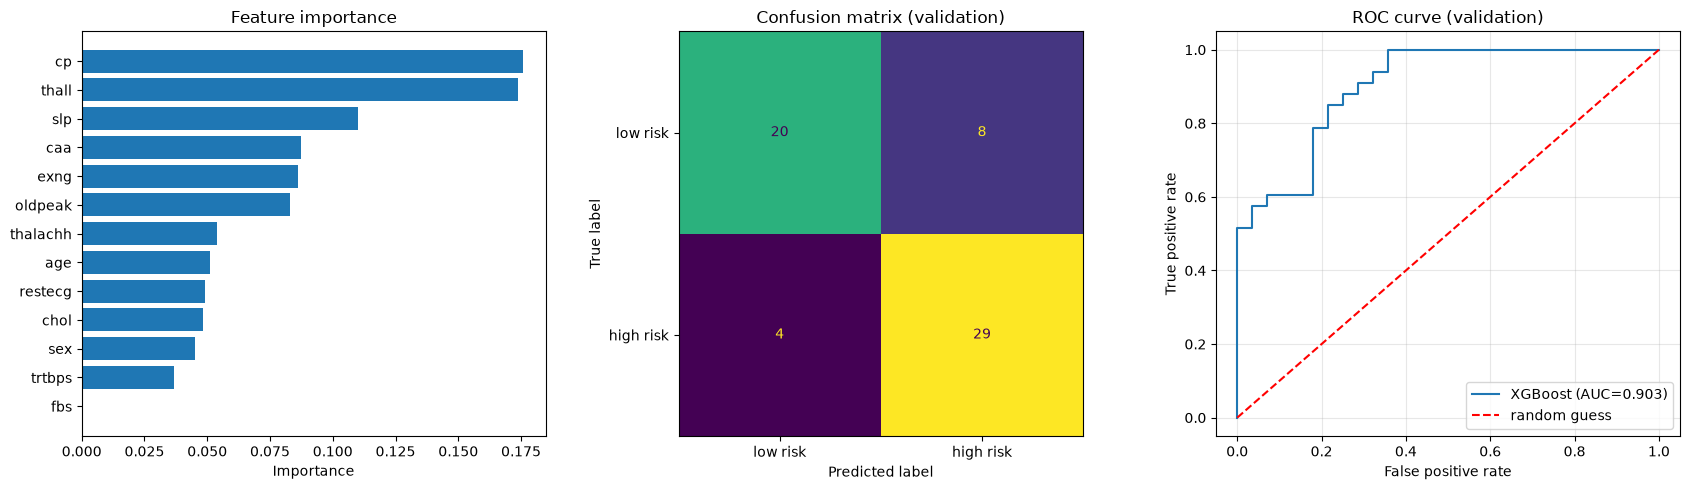

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)


def extract_texts_from_file(file_path):
    """Read the csv file and return a DataFrame."""
    return pd.read_csv(file_path)


def heart_classification(data):
    """
    Build an XGBoost model that classifies the risk of a heart attack
    (output: 1 = high chance, 0 = low chance). Visualize the model.

    Steps: stratified train/validation split -> hyperparameter search with
    cross-validation on the training part only -> a single evaluation on the
    held-out validation part -> plots.

    Returns:
        XGBClassifier: the fitted best model. (XGBoost is a tree ensemble, so
        it has no theta coefficients; feature importances are printed and plotted.)
    """
    X = data.drop(columns="output")
    y = data["output"]
    if y.nunique() < 2:
        raise ValueError("Target 'output' has a single class; need both 0 and 1 to train a classifier.")

    # cp, restecg, slp, thall are category codes, but trees split on thresholds,
    # so they work fine as plain integers (no one-hot encoding needed).
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)
    print(f"train: {len(X_train)} rows, validation: {len(X_val)} rows")

    # Choose parameters: grid search with 5-fold CV on the training data only.
    # Shallow trees and a small learning rate suit a dataset of a few hundred rows.
    param_grid = {
        "n_estimators": [100, 200, 300],
        "max_depth": [2, 3, 4],
        "learning_rate": [0.03, 0.1, 0.2],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
    }
    search = GridSearchCV(
        XGBClassifier(eval_metric="logloss", random_state=42),
        param_grid,
        scoring="roc_auc",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    model = search.best_estimator_
    print("best parameters:", search.best_params_)
    print(f"cross-validated ROC AUC (train only): {search.best_score_:.3f}")

    # Validation on data the model has never seen
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]
    print("\nValidation results")
    print(f"accuracy : {accuracy_score(y_val, y_pred):.3f}")
    print(f"precision: {precision_score(y_val, y_pred):.3f}")
    print(f"recall   : {recall_score(y_val, y_pred):.3f}")
    print(f"F1       : {f1_score(y_val, y_pred):.3f}")
    print(f"ROC AUC  : {roc_auc_score(y_val, y_proba):.3f}")
    print("\n", classification_report(y_val, y_pred, target_names=["low risk (0)", "high risk (1)"]))

    # Plots: feature importance, confusion matrix, ROC curve
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))

    importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()
    ax[0].barh(importance.index, importance.values, color="tab:blue")
    ax[0].set_title("Feature importance")
    ax[0].set_xlabel("Importance")

    ConfusionMatrixDisplay(confusion_matrix(y_val, y_pred),
                           display_labels=["low risk", "high risk"]).plot(ax=ax[1], colorbar=False)
    ax[1].set_title("Confusion matrix (validation)")

    fpr, tpr, _ = roc_curve(y_val, y_proba)
    ax[2].plot(fpr, tpr, label=f"XGBoost (AUC={roc_auc_score(y_val, y_proba):.3f})")
    ax[2].plot([0, 1], [0, 1], "r--", label="random guess")
    ax[2].set_xlabel("False positive rate")
    ax[2].set_ylabel("True positive rate")
    ax[2].set_title("ROC curve (validation)")
    ax[2].legend()
    ax[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model


if __name__ == "__main__":
    data = extract_texts_from_file("resources/heart.csv")
    heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

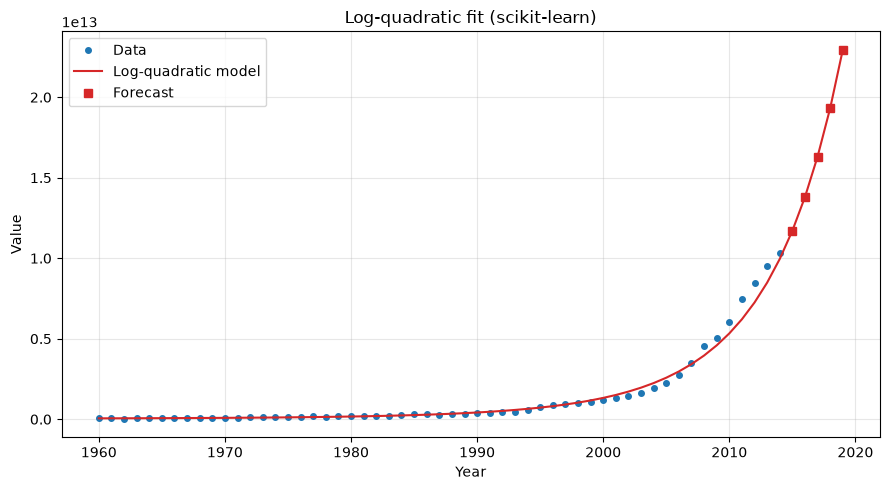

theta: [np.float64(24.771245818255554), np.float64(0.030080636384348075), np.float64(0.0012117874485176384)]


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures


def extract_texts_from_file(file_path):
    """Read the csv file and return a DataFrame."""
    return pd.read_csv(file_path)


def additional(data):
    """
    Fit a log-quadratic model with scikit-learn:
        log(Value) = theta0 + theta1*t + theta2*t^2,   t = Year - 1960
    predict the next 5 years and plot the result.

    Returns:
        list: theta = [theta0 (intercept), theta1, theta2]
    """
    years = data["Year"].values
    t = (years - 1960).reshape(-1, 1)
    value = data["Value"].values.astype(float)

    # quadratic regression on log(Value); TransformedTargetRegressor applies log
    # when fitting and exp when predicting, so predictions are on the original scale
    model = TransformedTargetRegressor(
        regressor=make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                                LinearRegression()),
        func=np.log,
        inverse_func=np.exp,
    )
    model.fit(t, value)

    lin = model.regressor_.named_steps["linearregression"]
    theta = [lin.intercept_, *lin.coef_]

    # predictions for the data years and the next 5 years
    future_years = np.arange(years.max() + 1, years.max() + 6)
    all_years = np.arange(years.min(), future_years.max() + 1)
    pred = model.predict((all_years - 1960).reshape(-1, 1))
    forecast = model.predict((future_years - 1960).reshape(-1, 1))

    plt.figure(figsize=(9, 5))
    plt.plot(years, value, "o", ms=4, label="Data")
    plt.plot(all_years, pred, color="tab:red", label="Log-quadratic model")
    plt.plot(future_years, forecast, "s", color="tab:red", label="Forecast")
    plt.xlabel("Year")
    plt.ylabel("Value")
    plt.title("Log-quadratic fit (scikit-learn)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return theta


data = extract_texts_from_file("resources/china_gdp.csv")
print("theta:", additional(data))

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



In [4]:
"""
Machine learning analysis on texts
Learning Agency Lab - Automated Essay Scoring 2.0
Target: holistic essay score (1-6) predicted from full_text.

Approach
  * word TF-IDF (1-2 grams) + character TF-IDF (3-5 grams, catches misspellings)
  * handcrafted features (length, sentences, paragraphs, lexical diversity ...)
  * two models:
      1. Logistic Regression  (classification)
      2. Ridge regression with rounding (treats the score as ordinal)
  * report: accuracy, macro / weighted F1, quadratic weighted kappa (QWK),
    classification report, confusion matrix (saved as PNG)

pip install pandas numpy scikit-learn scipy matplotlib seaborn kagglehub
"""

import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import kagglehub

kagglehub.login()

COMPETITION = "learning-agency-lab-automated-essay-scoring-2"
CSV_FILE = "train.csv"
RESOURCES_DIR = "resources"
RANDOM_STATE = 42


# --------------------------------------------------------------------------- #
# Data loading
# --------------------------------------------------------------------------- #
def load_dataset(competition=COMPETITION, csv_file=CSV_FILE):
    """
    Load train.csv of the competition.

    1. Looks for resources/train.csv (manual download from the Kaggle page).
    2. Otherwise downloads through kagglehub. This needs a Kaggle login
       (KAGGLE_USERNAME / KAGGLE_KEY or ~/.kaggle/kaggle.json) and you must
       accept the competition rules on the website first.
    """
    local_path = os.path.join(RESOURCES_DIR, csv_file)
    if os.path.exists(local_path):
        print(f"Loading local file: {local_path}")
        return pd.read_csv(local_path)

    print("Local file not found, downloading with kagglehub ...")
    path = kagglehub.competition_download(competition)
    return pd.read_csv(os.path.join(path, csv_file))


# --------------------------------------------------------------------------- #
# Features
# --------------------------------------------------------------------------- #
def handcrafted_features(texts):
    """Simple stylometric features. Essay length alone is a strong predictor."""
    rows = []
    for t in texts:
        words = re.findall(r"[A-Za-z']+", t)
        n_words = len(words)
        sentences = [s for s in re.split(r"[.!?]+", t) if s.strip()]
        paragraphs = [p for p in re.split(r"\n\s*\n|\n", t) if p.strip()]
        unique_words = len(set(w.lower() for w in words))
        rows.append(
            {
                "n_chars": len(t),
                "n_words": n_words,
                "n_sentences": len(sentences),
                "n_paragraphs": len(paragraphs),
                "avg_word_len": np.mean([len(w) for w in words]) if n_words else 0,
                "avg_sent_len": n_words / max(len(sentences), 1),
                "unique_ratio": unique_words / max(n_words, 1),
                "n_commas": t.count(","),
                "n_long_words": sum(len(w) > 6 for w in words),
            }
        )
    feats = pd.DataFrame(rows)
    # log-transform the heavy-tailed count features
    for col in ["n_chars", "n_words", "n_sentences", "n_paragraphs", "n_commas", "n_long_words"]:
        feats[col] = np.log1p(feats[col])
    return feats


def build_features(train_text, test_text):
    """Fit vectorizers on train only, return sparse matrices for train and test."""
    word_vec = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=3,
        max_features=60_000,
        sublinear_tf=True,
        strip_accents="unicode",
    )
    char_vec = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=5,
        max_features=100_000,
        sublinear_tf=True,
    )
    scaler = StandardScaler()

    Xw_tr = word_vec.fit_transform(train_text)
    Xc_tr = char_vec.fit_transform(train_text)
    Xh_tr = scaler.fit_transform(handcrafted_features(train_text))

    Xw_te = word_vec.transform(test_text)
    Xc_te = char_vec.transform(test_text)
    Xh_te = scaler.transform(handcrafted_features(test_text))

    X_tr = hstack([Xw_tr, Xc_tr, csr_matrix(Xh_tr)]).tocsr()
    X_te = hstack([Xw_te, Xc_te, csr_matrix(Xh_te)]).tocsr()
    return X_tr, X_te


# --------------------------------------------------------------------------- #
# Reporting
# --------------------------------------------------------------------------- #
def qwk(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")


def report(name, y_true, y_pred, labels):
    print("\n" + "=" * 70)
    print(f"{name}")
    print("=" * 70)
    print(f"Accuracy          : {accuracy_score(y_true, y_pred):.4f}")
    print(f"F1 (macro)        : {f1_score(y_true, y_pred, average='macro'):.4f}")
    print(f"F1 (weighted)     : {f1_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"Quadratic Kappa   : {qwk(y_true, y_pred):.4f}   <- competition metric")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, labels=labels, digits=3, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    print("Confusion matrix (rows = true, cols = predicted):")
    print(pd.DataFrame(cm, index=labels, columns=labels))
    return cm


def plot_confusion_matrices(cms, labels, path="confusion_matrices.png"):
    fig, axes = plt.subplots(1, len(cms), figsize=(7 * len(cms), 5.5))
    if len(cms) == 1:
        axes = [axes]
    for ax, (title, cm) in zip(axes, cms.items()):
        cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        sns.heatmap(
            cm_norm,
            annot=cm,
            fmt="d",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels,
            ax=ax,
            cbar_kws={"label": "row-normalised share"},
        )
        ax.set_title(title)
        ax.set_xlabel("Predicted score")
        ax.set_ylabel("True score")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.close(fig)
    print(f"\nSaved confusion matrices to {path}")


# --------------------------------------------------------------------------- #
# Main task
# --------------------------------------------------------------------------- #
def classify_text_ml(df):
    """
    Predict the holistic essay score (1-6) from full_text.

    Args:
        df (pd.DataFrame): DataFrame with columns 'full_text' and 'score'.

    Returns:
        dict: metrics for each model.
    """
    df = df.dropna(subset=["full_text", "score"]).copy()
    df["score"] = df["score"].astype(int)
    labels = sorted(df["score"].unique())

    print(f"Essays: {len(df)}")
    print("Score distribution:")
    print(df["score"].value_counts().sort_index())

    X_text = df["full_text"].values
    y = df["score"].values

    txt_tr, txt_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )

    print("\nBuilding features (word TF-IDF + char TF-IDF + handcrafted) ...")
    X_tr, X_te = build_features(txt_tr, txt_te)
    print(f"Feature matrix: train {X_tr.shape}, test {X_te.shape}")

    results, cms = {}, {}

    # ---- Model 1: Logistic Regression (classification) ------------------- #
    print("\nTraining Logistic Regression ...")
    clf = LogisticRegression(
        C=4.0,
        max_iter=500,
        class_weight="balanced",
        solver="lbfgs",
    )
    clf.fit(X_tr, y_tr)
    pred_clf = clf.predict(X_te)
    name = "Logistic Regression (classification)"
    cms[name] = report(name, y_te, pred_clf, labels)
    results[name] = {
        "accuracy": accuracy_score(y_te, pred_clf),
        "f1_macro": f1_score(y_te, pred_clf, average="macro"),
        "qwk": qwk(y_te, pred_clf),
    }

    # ---- Model 2: Ridge regression + rounding (ordinal view) ------------- #
    print("\nTraining Ridge regression ...")
    reg = Ridge(alpha=3.0, random_state=RANDOM_STATE)
    reg.fit(X_tr, y_tr)
    raw = reg.predict(X_te)
    pred_reg = np.clip(np.rint(raw), min(labels), max(labels)).astype(int)
    name = "Ridge regression + rounding (ordinal)"
    cms[name] = report(name, y_te, pred_reg, labels)
    results[name] = {
        "accuracy": accuracy_score(y_te, pred_reg),
        "f1_macro": f1_score(y_te, pred_reg, average="macro"),
        "qwk": qwk(y_te, pred_reg),
    }

    # ---- Summary ---------------------------------------------------------- #
    print("\n" + "=" * 70)
    print("SUMMARY")
    print("=" * 70)
    print(pd.DataFrame(results).T.round(4))

    plot_confusion_matrices(cms, labels)
    return results


if __name__ == "__main__":
    df = load_dataset()
    classify_text_ml(df)

Local file not found, downloading with kagglehub ...


100%|██████████| 11.9M/11.9M [00:03<00:00, 3.90MB/s]

Extracting files...


Essays: 17307
Score distribution:
score
1    1252
2    4723
3    6280
4    3926
5     970
6     156
Name: count, dtype: int64

Building features (word TF-IDF + char TF-IDF + handcrafted) ...
Feature matrix: train (13845, 140129), test (3462, 140129)

Training Logistic Regression ...


c:\Users\User\Desktop\ida-labs\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Logistic Regression (classification)
Accuracy          : 0.5930
F1 (macro)        : 0.5366
F1 (weighted)     : 0.5930
Quadratic Kappa   : 0.7594   <- competition metric

Classification report:
              precision    recall  f1-score   support

           1      0.498     0.546     0.521       251
           2      0.623     0.636     0.630       945
           3      0.607     0.582     0.594      1256
           4      0.596     0.605     0.601       785
           5      0.497     0.510     0.504       194
           6      0.435     0.323     0.370        31

    accuracy                          0.593      3462
   macro avg      0.543     0.534     0.537      3462
weighted avg      0.593     0.593     0.593      3462

Confusion matrix (rows = true, cols = predicted):
     1    2    3    4   5   6
1  137   88   18    5   3   0
2  103  601  222   16   3   0
3   35  261  731  214  14   1
4    0   14  232  475  62   2
5    0    0    1   84  99  10
6    0    0    0    3  18  10

Tr

Device: cuda
Downloaded to C:\Users\User\.cache\kagglehub\competitions\learning-agency-lab-automated-essay-scoring-2
Essays: 17307
score
1    1252
2    4723
3    6280
4    3926
5     970
6     156
Name: count, dtype: int64


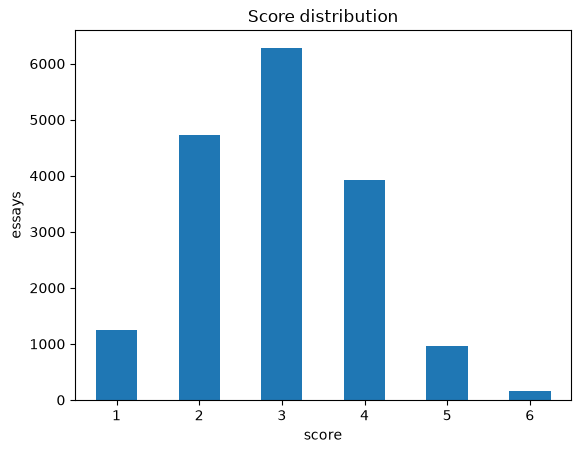

Train 12460 | Val 1385 | Test 3462
Token length: median 412, 30.0% of essays truncated at 512


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
C:\Users\User\AppData\Local\Temp\ipykernel_5848\1347189293.py:130: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  grad_scaler = torch.cud

Class weights: {1: np.float64(2.3), 2: np.float64(0.61), 3: np.float64(0.46), 4: np.float64(0.73), 5: np.float64(2.98), 6: np.float64(18.38)}
  epoch 1 step 50/3115 loss 1.7834
  epoch 1 step 100/3115 loss 1.7640
  epoch 1 step 150/3115 loss 1.7481
  epoch 1 step 200/3115 loss 1.7290
  epoch 1 step 250/3115 loss 1.7261
  epoch 1 step 300/3115 loss 1.7117
  epoch 1 step 350/3115 loss 1.6908
  epoch 1 step 400/3115 loss 1.6641
  epoch 1 step 450/3115 loss 1.6324
  epoch 1 step 500/3115 loss 1.5976
  epoch 1 step 550/3115 loss 1.5838
  epoch 1 step 600/3115 loss 1.5675
  epoch 1 step 650/3115 loss 1.5504
  epoch 1 step 700/3115 loss 1.5345
  epoch 1 step 750/3115 loss 1.5147
  epoch 1 step 800/3115 loss 1.5079
  epoch 1 step 850/3115 loss 1.4953
  epoch 1 step 900/3115 loss 1.4860
  epoch 1 step 950/3115 loss 1.4778
  epoch 1 step 1000/3115 loss 1.4680
  epoch 1 step 1050/3115 loss 1.4586
  epoch 1 step 1100/3115 loss 1.4515
  epoch 1 step 1150/3115 loss 1.4503
  epoch 1 step 1200/3115 lo

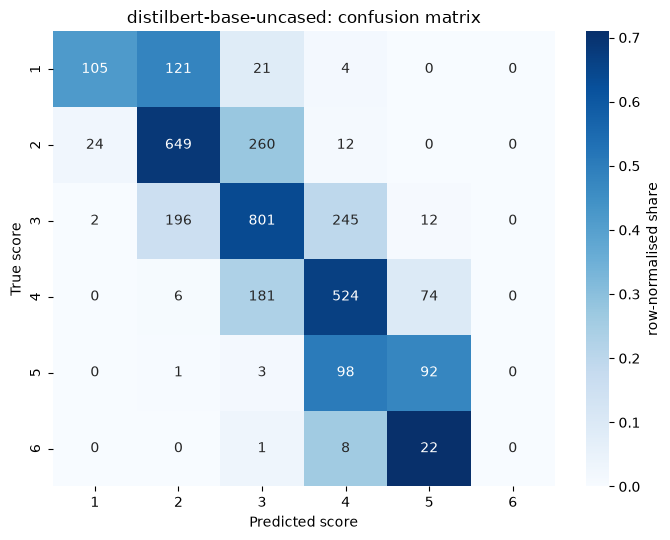


SUMMARY
accuracy    0.6271
f1_macro    0.4923
qwk         0.7807
dtype: float64


In [2]:
# !pip install -q transformers scikit-learn seaborn pandas matplotlib kagglehub   # uncomment if packages are missing

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, cohen_kappa_score,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)
import kagglehub

kagglehub.login()

MODEL_NAME = "distilbert-base-uncased"   # or "distilbert-base-uncased", "microsoft/deberta-v3-small"
MAX_LEN    = 512
BATCH_SIZE = 4                     # lower to 4 on CUDA out-of-memory
EPOCHS     = 3
LR         = 2e-5
SAMPLE     = 0                     # 0 = all essays; e.g. 2000 for a quick test
SEED       = 42


torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cpu":
    print("WARNING: no GPU found. Use SAMPLE=2000, EPOCHS=1 and distilbert for a first test.")


def qwk(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")


# ---------------------- 1. Load data ----------------------
COMPETITION = "learning-agency-lab-automated-essay-scoring-2"
local_path = os.path.join("resources", "train.csv")

if os.path.exists(local_path):
    df = pd.read_csv(local_path)
    print("Loaded", local_path)
else:
    path = kagglehub.competition_download(COMPETITION)
    df = pd.read_csv(os.path.join(path, "train.csv"))
    print("Downloaded to", path)

df = df.dropna(subset=["full_text", "score"]).copy()
df["score"] = df["score"].astype(int)
if SAMPLE:
    df = df.sample(n=min(SAMPLE, len(df)), random_state=SEED)

print("Essays:", len(df))
counts = df["score"].value_counts().sort_index()
print(counts)
counts.plot(kind="bar", title="Score distribution", xlabel="score", ylabel="essays", rot=0)
plt.show()

# ---------------------- 2. Split and labels ----------------------
scores = [int(s) for s in sorted(df["score"].unique())]
label2id = {s: i for i, s in enumerate(scores)}   # 1..6 -> 0..5
id2label = {i: s for s, i in label2id.items()}

texts = df["full_text"].values
y = df["score"].map(label2id).values

txt_tr, txt_te, y_tr, y_te = train_test_split(
    texts, y, test_size=0.2, stratify=y, random_state=SEED)
txt_tr, txt_val, y_tr, y_val = train_test_split(
    txt_tr, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)
print(f"Train {len(txt_tr)} | Val {len(txt_val)} | Test {len(txt_te)}")

# ---------------------- 3. Tokenization and loaders ----------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer)


class EssayDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding=False)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item


ds_tr, ds_val, ds_te = (EssayDataset(t, l) for t, l in
                        [(txt_tr, y_tr), (txt_val, y_val), (txt_te, y_te)])

dl_tr  = DataLoader(ds_tr,  batch_size=BATCH_SIZE,     shuffle=True, collate_fn=collator)
dl_val = DataLoader(ds_val, batch_size=BATCH_SIZE * 2, collate_fn=collator)
dl_te  = DataLoader(ds_te,  batch_size=BATCH_SIZE * 2, collate_fn=collator)

lens = [len(x) for x in ds_tr.enc["input_ids"]]
print(f"Token length: median {int(np.median(lens))}, "
      f"{np.mean(np.array(lens) >= MAX_LEN) * 100:.1f}% of essays truncated at {MAX_LEN}")

# ---------------------- 4. Model, loss, optimizer ----------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(scores), id2label=id2label, label2id=label2id,
).to(device)

class_counts = np.bincount(y_tr, minlength=len(scores))
class_weights = len(y_tr) / (len(scores) * np.maximum(class_counts, 1))
loss_fn = torch.nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float, device=device))

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(dl_tr) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

use_amp = device.type == "cuda"
grad_scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
print("Class weights:", dict(zip(scores, class_weights.round(2))))


@torch.no_grad()
def predict(loader):
    model.eval()
    preds = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        preds.append(model(**batch).logits.argmax(dim=-1).cpu().numpy())
    return np.concatenate(preds)


# ---------------------- 5. Training ----------------------
history = []
best_qwk, best_state = -1.0, None

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running = time.time(), 0.0
    for step, batch in enumerate(dl_tr, 1):
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), labels)
        grad_scaler.scale(loss).backward()
        grad_scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        grad_scaler.step(optimizer)
        grad_scaler.update()
        scheduler.step()
        running += loss.item()
        if step % 50 == 0:
            print(f"  epoch {epoch} step {step}/{len(dl_tr)} loss {running / step:.4f}")

    val_pred = predict(dl_val)
    val_acc, val_qwk = accuracy_score(y_val, val_pred), qwk(y_val, val_pred)
    history.append({"epoch": epoch, "train_loss": running / len(dl_tr),
                    "val_acc": val_acc, "val_qwk": val_qwk})
    print(f"Epoch {epoch}/{EPOCHS} | train loss {running / len(dl_tr):.4f} | "
          f"val acc {val_acc:.4f} | val QWK {val_qwk:.4f} | {time.time() - t0:.0f}s")

    if val_qwk > best_qwk:   # keep the best epoch by validation QWK
        best_qwk = val_qwk
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
print(f"\nLoaded best epoch (val QWK {best_qwk:.4f})")
print(pd.DataFrame(history).round(4))

# ---------------------- 6. Evaluation on the test set ----------------------
pred = predict(dl_te)
y_true = np.array([id2label[i] for i in y_te])
y_pred = np.array([id2label[i] for i in pred])

print("\n" + "=" * 60)
print(f"Accuracy        : {accuracy_score(y_true, y_pred):.4f}")
print(f"F1 (macro)      : {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"F1 (weighted)   : {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"Quadratic Kappa : {qwk(y_true, y_pred):.4f}   <- competition metric")
print("=" * 60)
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=scores, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=scores)
print("Confusion matrix (rows = true, cols = predicted):")
print(pd.DataFrame(cm, index=[f"true {s}" for s in scores],
                   columns=[f"pred {s}" for s in scores]))

cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues",
            xticklabels=scores, yticklabels=scores,
            cbar_kws={"label": "row-normalised share"})
plt.title(f"{MODEL_NAME}: confusion matrix")
plt.xlabel("Predicted score")
plt.ylabel("True score")
plt.tight_layout()
plt.savefig("confusion_matrix_bert.png", dpi=150)
plt.show()

bert_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "f1_macro": f1_score(y_true, y_pred, average="macro"),
    "qwk": qwk(y_true, y_pred),
}
print("\nSUMMARY")
print(pd.Series(bert_metrics).round(4))


# ---------------------- 7. Score a new essay (optional) ----------------------
@torch.no_grad()
def predict_score(text):
    model.eval()
    enc = tokenizer(text, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
    probs = torch.softmax(model(**enc).logits, dim=-1)[0].cpu().numpy()
    return id2label[int(probs.argmax())], dict(zip(scores, probs.round(3)))

# model.save_pretrained("bert_essay_model"); tokenizer.save_pretrained("bert_essay_model")
# print(predict_score("Some students think school should start later ..."))

Downloaded to C:\Users\User\.cache\kagglehub\competitions\learning-agency-lab-automated-essay-scoring-2
Essays: 17307 | median 412 tokens | 95th percentile 777 | max 1826
 max_len  essays_that_fit  pct_that_fit  pct_truncated
     128                0           0.0          100.0
     256             2448          14.1           85.9
     384             7611          44.0           56.0
     512            12166          70.3           29.7


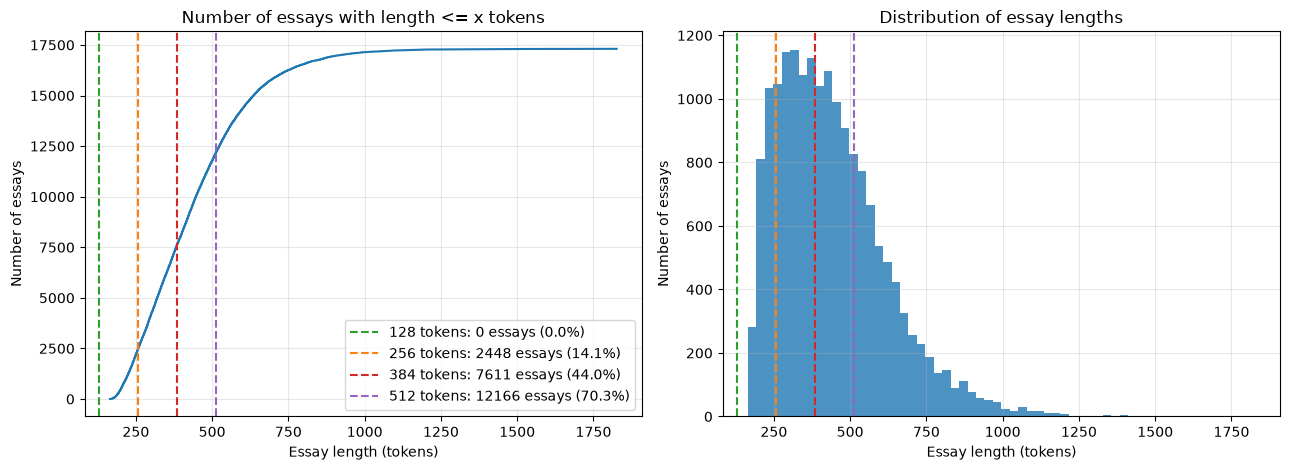

Essays with <= 300 tokens: 4210 of 17307 (24.3%)


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
import kagglehub

kagglehub.login()

MODEL_NAME = "bert-base-uncased"          # use the same tokenizer as your model
THRESHOLDS = [128, 256, 384, 512]         # lengths to mark on the plots
COMPETITION = "learning-agency-lab-automated-essay-scoring-2"

if "df" not in globals():
    path = kagglehub.competition_download(COMPETITION)
    df = pd.read_csv(os.path.join(path, "train.csv"))
    print("Downloaded to", path)
    
texts = df["full_text"].dropna().tolist()

hf_logging.set_verbosity_error()          # hide the "sequence longer than max" warning
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
lens = np.array([len(ids) for ids in tokenizer(texts, truncation=False)["input_ids"]])

n = len(lens)
print(f"Essays: {n} | median {int(np.median(lens))} tokens | "
      f"95th percentile {int(np.percentile(lens, 95))} | max {lens.max()}")

# table: how many essays fit completely within each length
table = pd.DataFrame({
    "max_len": THRESHOLDS,
    "essays_that_fit": [int((lens <= t).sum()) for t in THRESHOLDS],
    "pct_that_fit": [round((lens <= t).mean() * 100, 1) for t in THRESHOLDS],
    "pct_truncated": [round((lens > t).mean() * 100, 1) for t in THRESHOLDS],
})
print(table.to_string(index=False))

# plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# left: cumulative number of essays with length <= x
sorted_lens = np.sort(lens)
ax1.plot(sorted_lens, np.arange(1, n + 1), color="tab:blue")
for t, c in zip(THRESHOLDS, ["tab:green", "tab:orange", "tab:red", "tab:purple"]):
    fit = int((lens <= t).sum())
    ax1.axvline(t, ls="--", color=c,
                label=f"{t} tokens: {fit} essays ({fit / n * 100:.1f}%)")
ax1.set_title("Number of essays with length <= x tokens")
ax1.set_xlabel("Essay length (tokens)")
ax1.set_ylabel("Number of essays")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

# right: histogram of lengths
ax2.hist(lens, bins=60, color="tab:blue", alpha=0.8)
for t, c in zip(THRESHOLDS, ["tab:green", "tab:orange", "tab:red", "tab:purple"]):
    ax2.axvline(t, ls="--", color=c)
ax2.set_title("Distribution of essay lengths")
ax2.set_xlabel("Essay length (tokens)")
ax2.set_ylabel("Number of essays")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# check any length you like:
L = 300
print(f"Essays with <= {L} tokens: {(lens <= L).sum()} of {n} ({(lens <= L).mean() * 100:.1f}%)")